# Acoustic states with Gaussian mixture models

Provisional GMM analysis of the Stellwagen Bank SB01 hourly spectra, plus the
animal-data overview it will be compared against.

- All model code is in this notebook: the functions sit right above the
  cells that use them.
- Features are the **stand-in** matrix (33 standardized bands per hour from
  `all.csv`). Swap in the shared feature file once it exists.
- State numbers are arbitrary labels; keep them neutral until profiles and
  external data support names.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from itertools import combinations

from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "Data Mining Project").exists():
    ROOT = ROOT.parent
ACOUSTIC_CSV = ROOT / "Data Mining Project" / "all.csv"
TABLES = ROOT / "results" / "tables"
ASSIGNMENTS = ROOT / "results" / "cluster_assignments"
for d in (TABLES, ASSIGNMENTS):
    d.mkdir(parents=True, exist_ok=True)

%matplotlib inline
pd.set_option("display.width", 200)

# One fixed color per species, separate from the state colors (tab10).
SPECIES = ["atlantic_cod", "dolphins", "fin_whale", "humpback_whale",
           "minke_whale", "north_atlantic_right_whale", "sei_whale"]
SPECIES_COLORS = dict(zip(SPECIES, plt.get_cmap("Dark2").colors))

def species_colors(columns):
    return [SPECIES_COLORS[c] for c in columns]

## 1. Animal data

Built by `scripts/build_animal_tables.py` (see `docs/ANIMAL_AUDIT.md`): blue
whale dropped, daily species one row per UTC day, days with fewer than 20
acoustic hours flagged, cod hourly presence is our own binning of grunt events.

In [2]:
daily = pd.read_csv(ROOT / "data/processed/animals_daily.csv", parse_dates=["date"])
hourly = pd.read_csv(ROOT / "data/processed/animals_hourly.csv", parse_dates=["time"])

kept = daily[daily["keep_day"]]
summary = pd.concat([
    kept.groupby("animal")["presence"].agg(units="size", present="sum").assign(unit="day"),
    hourly.groupby("animal")["presence"].agg(units="size", present="sum").assign(unit="hour"),
])
summary["present_pct"] = (100 * summary["present"] / summary["units"]).round(1)
summary

,units,present,unit,present_pct
animal,,,,
fin_whale,733,232,day,31.7
humpback_whale,733,422,day,57.6
minke_whale,917,127,day,13.8
north_atlantic_right_whale,733,51,day,7.0
sei_whale,733,99,day,13.5
atlantic_cod,18106,429,hour,2.4
dolphins,26842,5020,hour,18.7


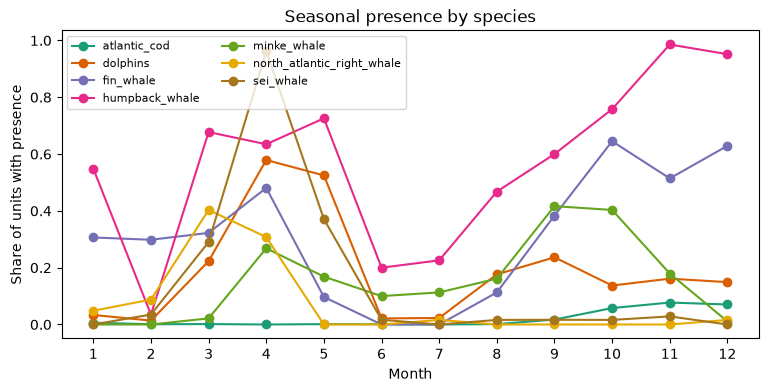

In [3]:
# Monthly share of days (or hours) with presence, per species
monthly = pd.concat([
    kept.assign(month=kept["date"].dt.month)[["animal", "month", "presence"]],
    hourly.assign(month=hourly["time"].dt.month)[["animal", "month", "presence"]],
]).groupby(["animal", "month"])["presence"].mean().unstack("animal")

fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(ax=ax, marker="o", color=species_colors(monthly.columns))
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Share of units with presence")
ax.set_title("Seasonal presence by species")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 2. Features

One row per hour, 33 bands in dB; missing hours are left out, never imputed.
Each band is standardized before fitting.

In [4]:
def load_features():
    """Return (meta, X_raw, bands): meta has time/deployment, X_raw is hours x bands in dB."""
    long = pd.read_csv(ACOUSTIC_CSV)
    long["time"] = pd.to_datetime(long["time"], utc=True)
    wide = long.pivot_table(
        index=["time", "deployment"], columns="frequency", values="sound_pressure_levels"
    ).sort_index(axis=1)
    wide = wide.dropna()  # missing hours stay missing; never impute for clustering
    meta = wide.index.to_frame(index=False)
    return meta, wide.to_numpy(), wide.columns.to_numpy()

In [5]:
meta, X_raw, bands = load_features()
X = StandardScaler().fit_transform(X_raw)
print(f"{X.shape[0]:,} hours x {X.shape[1]} bands")

26,873 hours x 33 bands


## 3. Choosing K (BIC)

In [ ]:
K_RANGE = range(3, 15)
COVARIANCE_TYPES = ["full", "diag"]
SEEDS = [42, 36, 67, 201]


print("K range:", list(K_RANGE), "| covariance:", COVARIANCE_TYPES, "| seeds:", SEEDS)


def fit_gmm(X, k, cov, seed):
    """build and fit one GaussianMixture, then return the fitted model.

    Beyond n_components / covariance_type / random_state, decide on:
    - max_iter: EM stops here even if not converged (check model.converged_).
    - n_init: EM restarts inside one fit, keeping the best. Overlaps with
      looping over SEEDS; pick one approach and know why.
    - reg_covar: small value added to covariance diagonals so they stay
      invertible. Our bands are highly correlated, so full covariances can
      be nearly singular.
    - init_params: how initial means are chosen ("kmeans", "k-means++",
      "random", ...).
    """
    return GaussianMixture(
        n_components = k,
        covariance_type = cov,
        random_state=seed,
        n_init=1,
        max_iter=500,
        reg_covar=1e-3,
        init_params="kmeans",
    ).fit(X)


def select_k(X):
    """
    Fit every (K, covariance type, seed) and score it.

    Return a DataFrame with one row per fit and at least these columns:
        k, covariance, seed, bic, aic, converged
    The fitted model has .bic(X), .aic(X), .converged_, .n_iter_.

    Understand before you write it: BIC = -2 * log-likelihood + p * ln(n),
    where p = number of free parameters and n = number of hours. What does
    the penalty term do as K grows, and why does full covariance pay more
    than diag?
    """
    rows = []
    for cov in COVARIANCE_TYPES:
        for k in K_RANGE:
            for seed in SEEDS:
                gmm = fit_gmm(X, k, cov, seed)
                rows.append({
                    "k": k,
                    "covariance": cov,
                    "seed": seed,
                    "bic": gmm.bic(X),
                    "aic": gmm.aic(X),
                    "log_likelihood": gmm.score(X) * len(X),  # score() is the per-sample mean
                    "converged": gmm.converged_,
                    "iterations": gmm.n_iter_,
                })
            print(f"done: {cov} K={k}")
    return pd.DataFrame(rows)

K range: [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | covariance: ['full', 'diag'] | seeds: [42, 36, 67, 201]


In [7]:
RERUN_SWEEP = False

sweep_path = TABLES / "gmm_model_selection.csv"
if RERUN_SWEEP or not sweep_path.exists():
    sweep = select_k(X)
    sweep.to_csv(sweep_path, index=False)
else:
    sweep = pd.read_csv(sweep_path)
print("fits:", len(sweep), "| not converged:", int((~sweep["converged"]).sum()))

fits: 96 | not converged: 0


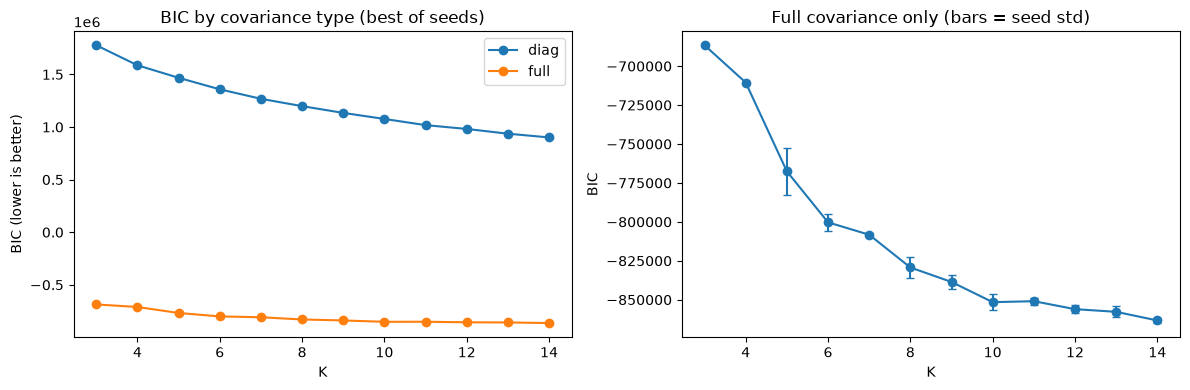

,min,std,change
k,,,
3,-686565.0,1.0,NaN
4,-710515.0,3.0,-23950.0
5,-767575.0,15116.0,-57060.0
6,-800303.0,5332.0,-32728.0
7,-808280.0,1119.0,-7977.0
8,-829300.0,6798.0,-21020.0
9,-838605.0,4259.0,-9305.0
10,-851574.0,4920.0,-12969.0
11,-850957.0,2159.0,617.0


In [8]:
best = sweep.groupby(["covariance", "k"])["bic"].agg(["min", "std"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cov, g in best.groupby(level="covariance"):
    axes[0].plot(g.index.get_level_values("k"), g["min"], marker="o", label=cov)
axes[0].set(title="BIC by covariance type (best of seeds)", xlabel="K", ylabel="BIC (lower is better)")
axes[0].legend()

full = best.loc["full"]
axes[1].errorbar(full.index, full["min"], yerr=full["std"], marker="o", capsize=3)
axes[1].set(title="Full covariance only (bars = seed std)", xlabel="K", ylabel="BIC")
plt.tight_layout()
plt.show()

full.assign(change=full["min"].diff()).round(0)

## 4. Final model

In [9]:
def stability(X, k, cov):
    """how consistent are the states across seeds?

    Fit the chosen (k, cov) once per seed, get hard labels with .predict(X),
    then compute adjusted_rand_score for every pair of seed runs
    (itertools.combinations helps). Return (mean ARI, min ARI).

    Why ARI and not "fraction of labels equal"? Seed 0's state 2 might be
    seed 1's state 4: the numbering is arbitrary, only the grouping matters.
    """
    labels = [fit_gmm(X, k, cov, seed).predict(X) for seed in SEEDS]
    scores = [adjusted_rand_score(a, b) for a, b in combinations(labels, 2)]
    return float(np.mean(scores)), float(np.min(scores))


def assign_states(gmm, X):
    """
    Turn a fitted model into per-hour assignments.

    Return (state, confidence, probs):
    - probs: hours x K matrix of P(state | spectrum); rows sum to 1
      (this is the E-step "responsibility")
    - state: the most likely state per hour
    - confidence: that state's probability

    What would a confidence of 0.55 mean for an hour, compared with 0.99?
    """
    probs = gmm.predict_proba(X)
    state = probs.argmax(axis=1)
    confidence = probs.max(axis=1)
    return state, confidence, probs


def state_profiles(X_raw, state):
    """
    Mean spectrum of each state in dB (rows = states, columns = bands).

    Use X_raw (dB), not the standardized X: profiles should be readable as
    actual sound levels. Alternatively, think about what gmm.means_ holds and
    how scaler.inverse_transform relates to it. Are the two approaches the
    same thing? (Hint: hard vs. soft membership.)
    """
    return pd.DataFrame(X_raw).groupby(state).mean()

In [10]:
K, COV = 6, "full"

ari_mean, ari_min = stability(X, K, COV)
print(f"Stability at K={K} ({COV}): mean ARI {ari_mean:.3f}, min {ari_min:.3f}")

# Final model: the best-BIC run among SEEDS (lowest BIC wins).
gmm = min((fit_gmm(X, K, COV, seed) for seed in SEEDS), key=lambda m: m.bic(X))
print(f"Final model: seed {gmm.random_state} (BIC {gmm.bic(X):,.0f})")
state, confidence, probs = assign_states(gmm, X)
states = meta.assign(state=state, confidence=confidence)

state_summary = states.groupby("state").agg(
    hours=("state", "size"),
    median_confidence=("confidence", "median"),
    low_confidence_share=("confidence", lambda c: (c < 0.8).mean()),
)
state_summary["share"] = state_summary["hours"] / len(states)
state_summary.round(3)

Stability at K=6 (full): mean ARI 0.756, min 0.644


Final model: seed 67 (BIC -800,303)


,hours,median_confidence,low_confidence_share,share
state,,,,
0,5697,0.999,0.072,0.212
1,6514,1.000,0.052,0.242
2,1341,1.000,0.083,0.050
3,8654,1.000,0.079,0.322
4,3267,0.998,0.129,0.122
5,1400,1.000,0.054,0.052


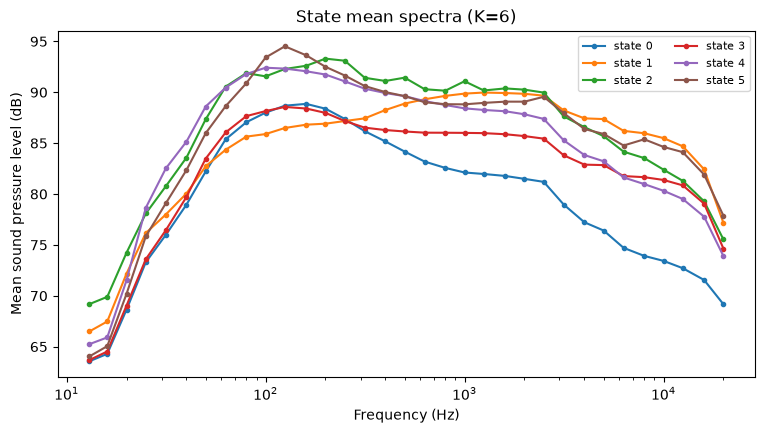

In [11]:
profiles = state_profiles(X_raw, state)

fig, ax = plt.subplots(figsize=(9, 4.5))
for s, row in profiles.iterrows():
    ax.plot(bands, row.values, marker=".", label=f"state {s}")
ax.set_xscale("log")
ax.set(xlabel="Frequency (Hz)", ylabel="Mean sound pressure level (dB)", title=f"State mean spectra (K={K})")
ax.legend(fontsize=8, ncol=2)
plt.show()

### What the states are

**Why different states:** wind and waves add high-pitched hiss; ships add a
low-to-mid rumble; animals call; some hours are just quiet.

**State meanings** (this run: K = 6, seed 67)

| State | Share | What it seems to be |
|---:|---:|---|
| 0 | 21% | Calm and quiet; low wind, small waves; mostly summer |
| 1 | 24% | Windy and rough; 3x the wind, extra high-pitched noise; mostly winter |
| 2 | 5% | Loud across all pitches; rare; winter; cause unclear |
| 3 | 32% | Ordinary background; all year |
| 4 | 12% | Extra low-to-mid rumble without wind; possibly ships |
| 5 | 5% | Peak around 125 Hz; calm; most ship time; April; ships or spring animals |

States 0 and 1 match the weather; 2, 4 and 5 still need testing.

**Why we're doing this:** check whether an algorithm that only hears the ocean
finds real patterns (weather, ships, whale seasons) without being told; next,
compare daily animal observations with daily summaries of the states.

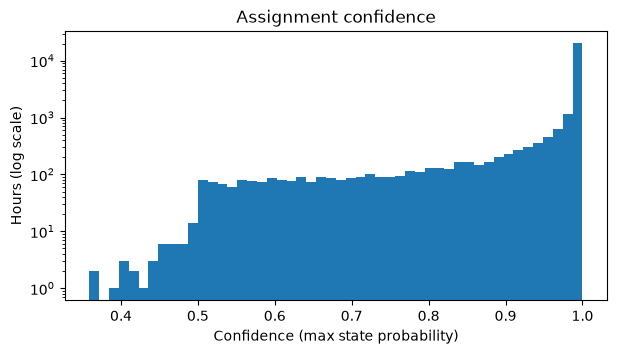

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(confidence, bins=50)
ax.set_yscale("log")
ax.set(xlabel="Confidence (max state probability)", ylabel="Hours (log scale)", title="Assignment confidence")
plt.show()

## 5. First checks against time and vessels

Descriptive only; these are not interpretations yet.

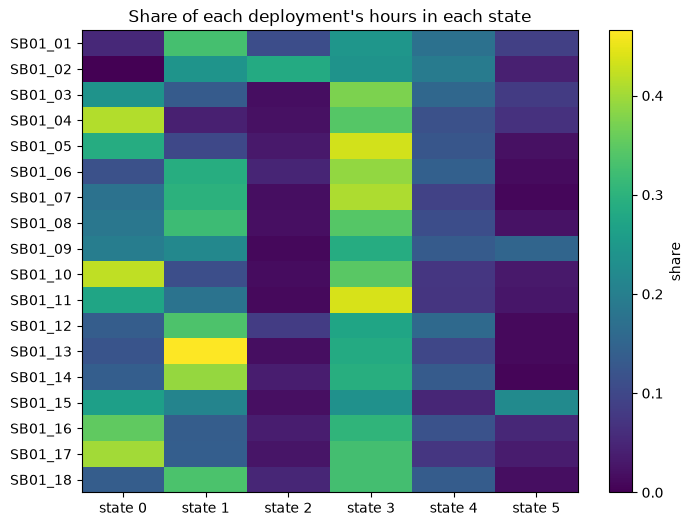

In [13]:
by_dep = pd.crosstab(states["deployment"], states["state"], normalize="index")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(by_dep.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(K), [f"state {s}" for s in by_dep.columns])
ax.set_yticks(range(len(by_dep)), by_dep.index)
ax.set_title("Share of each deployment's hours in each state")
fig.colorbar(im, ax=ax, label="share")
plt.show()

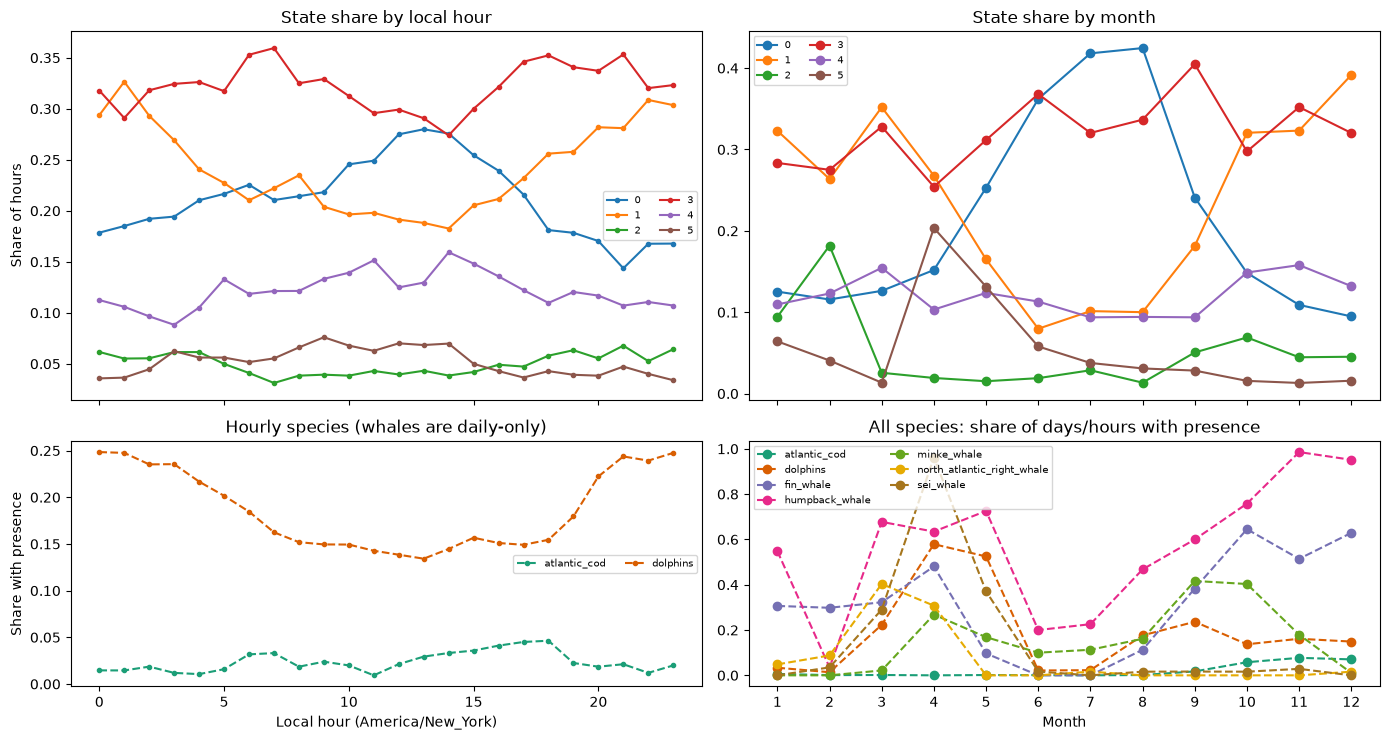

In [14]:
times = pd.to_datetime(states["time"], utc=True)
local_hour = times.dt.tz_convert("America/New_York").dt.hour
by_hour = pd.crosstab(local_hour, states["state"], normalize="index")
by_month = pd.crosstab(times.dt.month, states["state"], normalize="index")

# Animals at native resolution: whales are daily, so they only appear on the
# month panel; dolphins and cod are hourly, so they also appear by hour.
animal_hour = (
    hourly.assign(hour=hourly["time"].dt.tz_convert("America/New_York").dt.hour)
    .groupby(["hour", "animal"])["presence"].mean().unstack("animal")
)

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex="col",
                         gridspec_kw={"height_ratios": [3, 2]})
by_hour.plot(ax=axes[0, 0], marker=".")
axes[0, 0].set(ylabel="Share of hours", title="State share by local hour")
by_month.plot(ax=axes[0, 1], marker="o")
axes[0, 1].set(title="State share by month")

animal_hour.plot(ax=axes[1, 0], marker=".", linestyle="--", color=species_colors(animal_hour.columns))
axes[1, 0].set(xlabel="Local hour (America/New_York)", ylabel="Share with presence",
               title="Hourly species (whales are daily-only)")
monthly.plot(ax=axes[1, 1], marker="o", linestyle="--", color=species_colors(monthly.columns))
axes[1, 1].set(xlabel="Month", title="All species: share of days/hours with presence")
axes[1, 1].set_xticks(range(1, 13))

for ax in axes.flat:
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

Animal panels use each product's own coverage window (whales stop in
2020-11, minke 2021-05, cod is missing six deployments), while the state panels
use all acoustic hours. Read them as context, not as a direct comparison; the
day-level state vs. presence comparison comes next.

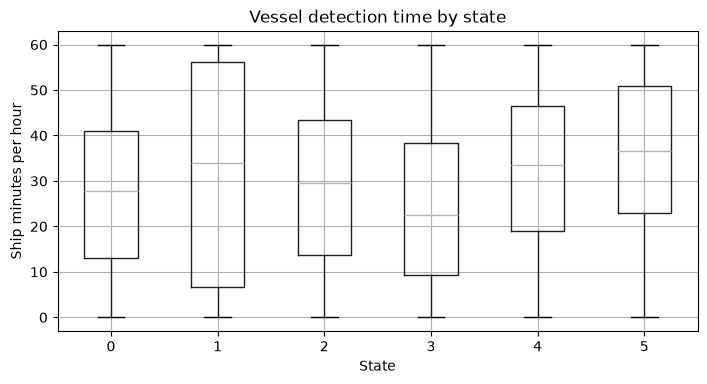

In [15]:
ships = pd.read_csv(ROOT / "Data Mining Project/ships_hourly.csv")
ships["time"] = pd.to_datetime(ships["hour_utc"], utc=True)
with_ships = states.assign(time=times).merge(ships[["time", "ship_minutes"]], on="time", how="left")

fig, ax = plt.subplots(figsize=(8, 4))
with_ships.boxplot(column="ship_minutes", by="state", ax=ax, showfliers=False)
ax.set(xlabel="State", ylabel="Ship minutes per hour", title="Vessel detection time by state")
plt.suptitle("")
plt.show()

In [16]:
ordered = states.assign(time=times).sort_values("time")
run_id = (ordered["state"] != ordered["state"].shift()).cumsum().rename("run")
runs = ordered.groupby(run_id).agg(state=("state", "first"), hours=("state", "size"))
runs.groupby("state")["hours"].describe()[["count", "50%", "75%", "max"]]

,count,50%,75%,max
state,,,,
0,1735.0,2.0,4.0,35.0
1,1803.0,2.0,4.0,82.0
2,638.0,1.0,2.0,105.0
3,3309.0,2.0,3.0,26.0
4,2102.0,1.0,2.0,14.0
5,478.0,2.0,3.0,23.0


Note: run lengths here do not yet break at deployment gaps or missing
hours; do that before reporting state dynamics.

## 6. Save assignments

In [17]:
out = states.copy()
for j in range(K):
    out[f"p_state_{j}"] = np.round(probs[:, j], 4)
out_path = ASSIGNMENTS / f"gmm_k{K}_{COV}.csv"
out.to_csv(out_path, index=False)
print("wrote", out_path.relative_to(ROOT))

wrote results/cluster_assignments/gmm_k6_full.csv
